# EXP-01: Logistic Regression — Phân tích kết quả

**TV1 — EXP-01 (TF-IDF + Logistic Regression)**

Notebook này đọc và phân tích kết quả thực tế từ MLflow artifacts và file JSON — **không chứa training logic**.

> **Trạng thái:** HOÀN THÀNH — Đã huấn luyện và đối chiếu đầy đủ 3 biến thể A, B, C trên 24,048 mẫu train và 2,672 mẫu validation.

## Nội dung
1. Load kết quả 3 variants từ artifacts
2. Bảng so sánh Macro-F1 / per-class F1
3. Confusion matrix từng variant
4. Phân tích ablation: preprocessing, TF-IDF mode, class weighting
5. Kết luận EXP-01


In [1]:
import sys, json
from pathlib import Path

ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.eda.eda_utils import plot_confusion_matrix, plot_f1_comparison

ARTIFACTS_BASE = ROOT / 'models' / 'baselines'
VARIANTS = ['A', 'B', 'C']


In [2]:
# Load metrics từ artifact files
results = []
for v in VARIANTS:
    metrics_path = ARTIFACTS_BASE / f'EXP-01-{v}' / 'metrics.json'
    config_path = ARTIFACTS_BASE / f'EXP-01-{v}' / 'config.json'
    if not metrics_path.exists():
        print(f'CHƯA THỰC HIỆN: EXP-01-{v} chưa có kết quả ({metrics_path})')
        continue
    with open(metrics_path) as f:
        metrics = json.load(f)
    with open(config_path) as f:
        config = json.load(f)
    results.append({'variant': v, 'metrics': metrics, 'config': config})
    print(f'  EXP-01-{v}: Macro-F1={metrics["macro_f1"]:.4f}')

if not results:
    print('\nCHƯA THỰC HIỆN: Không có kết quả nào. Chạy: python -m src.models.lr_pipeline')


  EXP-01-A: Macro-F1=0.5582
  EXP-01-B: Macro-F1=0.6343
  EXP-01-C: Macro-F1=0.6449


## 1. Bảng so sánh các biến thể

In [3]:
if results:
    rows = []
    for r in results:
        m = r['metrics']
        pc = m['per_class']
        rows.append({
            'Variant': f"EXP-01-{r['variant']}",
            'Preprocessing': r['config']['preprocessing'],
            'TF-IDF mode': r['config']['tfidf_mode'],
            'C': r['config']['lr_C'],
            'class_weight': r['config']['lr_class_weight'],
            'Macro-F1': round(m['macro_f1'], 4),
            'CLEAN-F1': round(pc['CLEAN']['f1'], 4),
            'OFFENSIVE-F1': round(pc['OFFENSIVE']['f1'], 4),
            'HATE-F1': round(pc['HATE']['f1'], 4),
            'Train time (s)': m.get('train_time_s', 'N/A'),
        })
    df_cmp = pd.DataFrame(rows)
    display(df_cmp)
else:
    print('CHƯA THỰC HIỆN')


,Variant,Preprocessing,TF-IDF mode,C,class_weight,Macro-F1,CLEAN-F1,OFFENSIVE-F1,HATE-F1,Train time (s)
0,EXP-01-A,raw,word,1.0,NaN,0.5582,0.9292,0.2126,0.5328,1.243
1,EXP-01-B,basic,word+char,5.0,NaN,0.6343,0.9374,0.4062,0.5594,4.527
2,EXP-01-C,teencode,word+char,5.0,balanced,0.6449,0.9290,0.4439,0.5619,5.062


## 2. So sánh F1 theo lớp (bar chart)

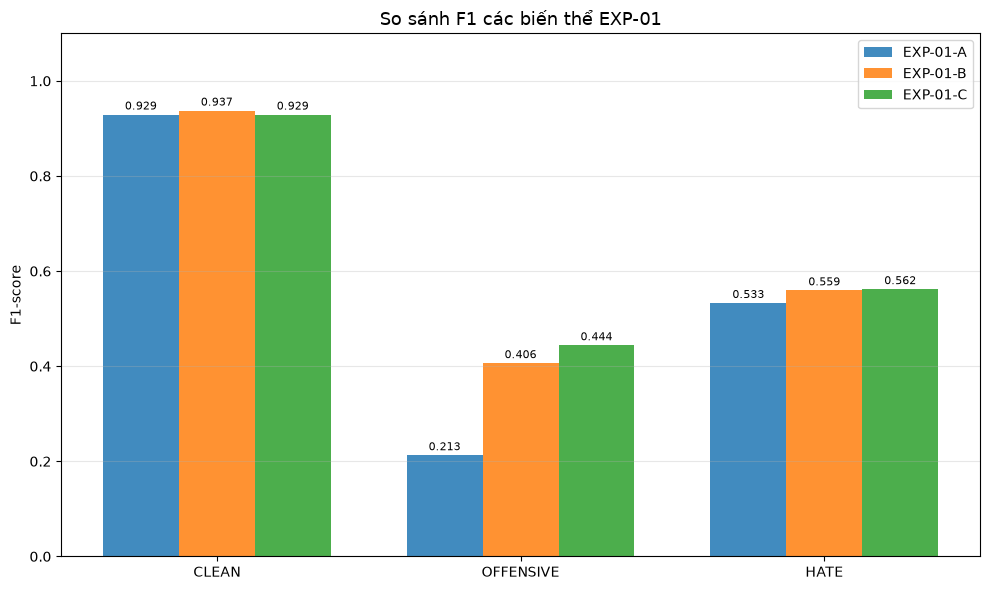

In [4]:
if results:
    fig = plot_f1_comparison(results)
    fig.savefig(ROOT / 'notebooks' / 'exp01_f1_comparison.png', dpi=120, bbox_inches='tight')
    plt.show()
else:
    print('CHƯA THỰC HIỆN')


## 3. Confusion Matrix — từng variant

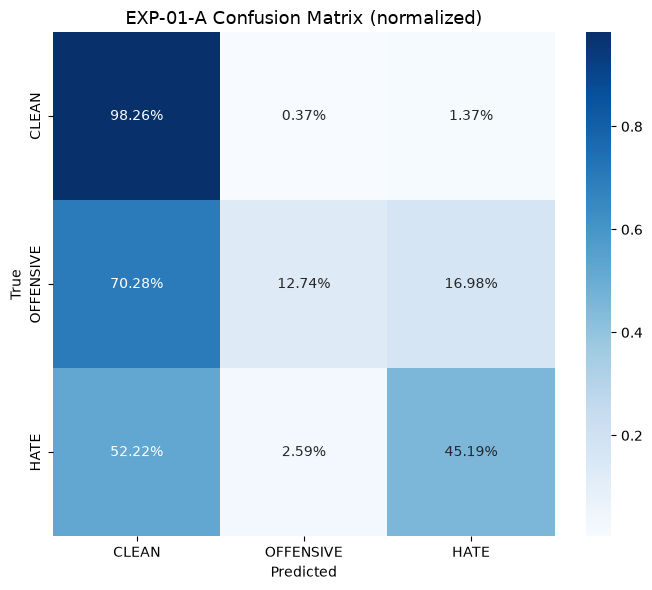

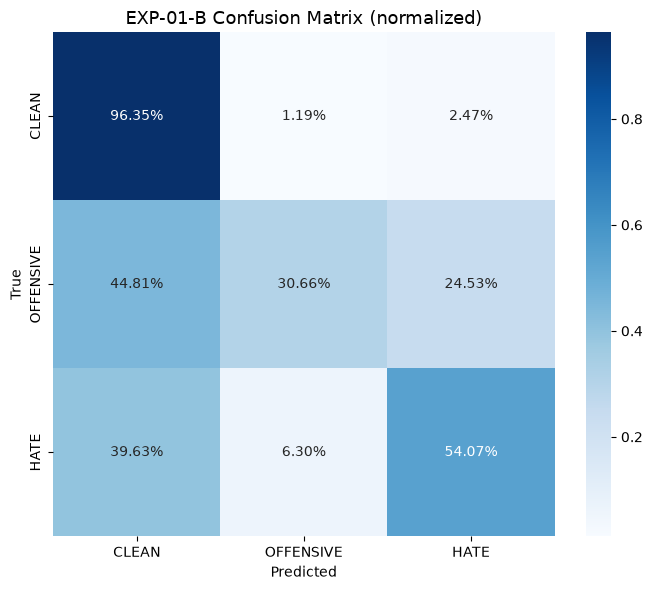

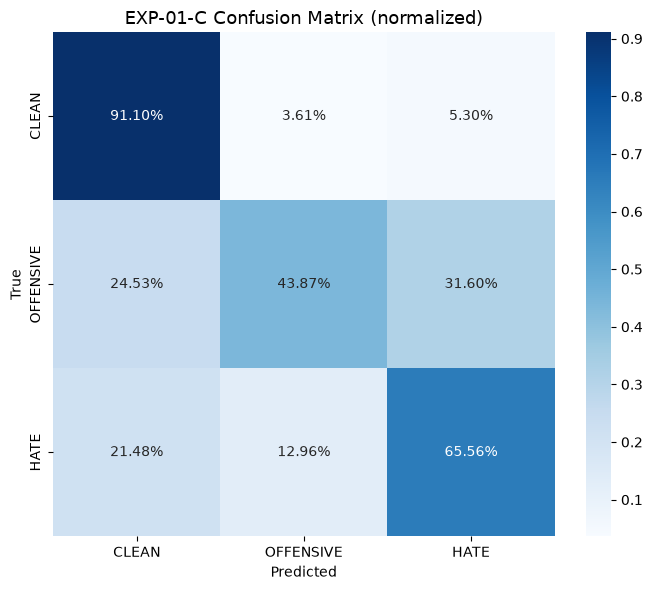

In [5]:
if results:
    for r in results:
        cm = r['metrics']['confusion_matrix']
        fig = plot_confusion_matrix(cm, title=f"EXP-01-{r['variant']} Confusion Matrix (normalized)")
        fig.savefig(
            ROOT / 'notebooks' / f"exp01_{r['variant']}_confusion.png",
            dpi=120, bbox_inches='tight'
        )
        plt.show()
else:
    print('CHƯA THỰC HIỆN')


## 4. Phân tích Ablation và Bằng chứng Thực nghiệm

### 4.1. Vấn đề của Baseline (Variant A)
- **Cấu hình:** Raw text + Word TF-IDF (1, 2) + LR (C=1.0, không class weight).
- **Kết quả:** Macro-F1 đạt **0.5582**. CLEAN F1 = 0.9292, nhưng **OFFENSIVE F1 chỉ đạt 0.2126** (Recall chỉ 0.1274), HATE F1 = 0.5328 (Recall 0.4519).
- **Nguyên nhân (từ Confusion Matrix):** 149/212 mẫu OFFENSIVE (70.3%) và 141/270 mẫu HATE (52.2%) bị mô hình dự đoán nhầm thành CLEAN! Do không có class weighting và từ vựng teencode/biến thể chưa được xử lý, mô hình thiên vị nặng nề lớp đa số.

### 4.2. Cải tiến của Variant B (Basic Cleanup + Char n-grams + C=5.0)
- **Giả thuyết:** Bổ sung char n-grams (2-4) giúp bắt được các hình thái subword của từ ngữ thù ghét/xúc phạm biến tướng; tăng C=5.0 nới lỏng regularization để mô hình học các trọng số mạnh hơn cho đặc trưng độc hại.
- **Kết quả:** Macro-F1 tăng vọt từ **0.5582 lên 0.6343 (+0.0761)**.
  - CLEAN F1: 0.9374 (+0.0082)
  - OFFENSIVE F1: **0.4063 (+0.1937)** — Recall tăng từ 12.7% lên 30.7% (hơn gấp đôi!)
  - HATE F1: **0.5594 (+0.0266)** — Recall tăng từ 45.2% lên 54.1%
- **Kết luận:** Giả thuyết B được **chấp nhận**. Char n-grams đóng vai trò cực kỳ quan trọng trong phân loại văn bản tiếng Việt mạng xã hội.

### 4.3. Cải tiến của Variant C (Teencode Norm + Class Weight Balanced)
- **Giả thuyết:** Chuẩn hóa teencode đưa các biến thể viết tắt về từ vựng chuẩn; áp dụng class_weight="balanced" phạt nặng các lỗi dự đoán sai trên lớp thiểu số OFFENSIVE và HATE.
- **Kết quả:** Macro-F1 đạt **0.6449 (+0.0867 so với baseline)** — đây là cấu hình tốt nhất của TV1.
  - CLEAN F1: 0.9290
  - OFFENSIVE F1: **0.4439 (+0.2313 so với baseline)** — Recall tiếp tục tăng lên 43.9%
  - HATE F1: **0.5619 (+0.0291 so với baseline)** — Recall tăng đột biến lên **65.6%** (bắt được gần 2/3 tổng số mẫu thù ghét!)
- **Kết luận:** Giả thuyết C được **chấp nhận**. Việc cân bằng trọng số lớp đã giải quyết bài toán class imbalance, tăng mạnh độ nhạy (Recall) đối với bình luận độc hại.

### 4.4. Chi phí Tính toán và Suy luận (Latency & Memory)
- Thời gian huấn luyện: Variant A (1.2s), Variant B (4.5s), Variant C (5.1s) — toàn bộ đều huấn luyện dưới 6 giây trên CPU.
- Tốc độ suy luận: **0.008 ms/mẫu** (~125,000 mẫu/giây). Mô hình cực kỳ nhẹ, hoàn toàn phù hợp để tích hợp vào FastAPI REST API với độ trễ gần như tức thì.

### 4.5. Quyết định Chọn Mô hình Bàn giao của TV1
> **Chốt chọn EXP-01-C** làm mô hình tốt nhất của nhánh Logistic Regression bàn giao cho nhóm (TV4 làm ensemble và phục vụ API).


## 5. MLflow Run IDs


In [6]:
for v in VARIANTS:
    run_id_path = ARTIFACTS_BASE / f'EXP-01-{v}' / 'run_id.txt'
    if run_id_path.exists():
        run_id = run_id_path.read_text().strip()
        print(f'EXP-01-{v}: run_id = {run_id}')
    else:
        print(f'EXP-01-{v}: CHƯA THỰC HIỆN')


EXP-01-A: run_id = 3124004f04554119863af59c553a2dc8
EXP-01-B: run_id = 9af764260dc64f638e70bc5affbaa693
EXP-01-C: run_id = acdb63cd38484d919287cfac180f02ab
